---
title: ""
lang: uk
format:
  typst:
    mainfont: "Times New Roman"
    fontsize: 14pt
    margin: { x: 2.5cm, y: 2.5cm }
  docx: default
  pdf:
    pdf-engine: lualatex
    mainfont: "Times New Roman"
---


```{=typst}
// Configure the page.
#set page(
  paper: "a4",
  // The margins depend on the paper size.
  margin: (x: 2cm, y: 1.5cm),
  numbering:  (current, total) => if current > 1 { current }, number-align: right, 
)

// Configure styling
#set par(
  leading: 0.8em,
  spacing: 1em,
  justify: true,
)
#show table: set text(size: 9pt)

#align(top + center)[
  Міністерство освіти і науки України \
  Національний університет «Львівська політехніка» \
  Кафедра систем штучного інтелекту \
  \
  #image("logo.png", width: 6cm)
  \
  #set par(spacing: 0.4em)
  #text(size: 24pt, weight: "bold")[Звіт]
  #set par(spacing: 0.8em)

  *про виконання лабораторної роботи № 7* \
  _з дисципліни:_ «Обробка мови методами штучного інтелекту»
]

#align(bottom + right)[
  Виконав: \
  студент групи ШІ-42 \
  Горишевський Олексій Олександрович
]

#pagebreak()
```

# Fine-tuning BERT for text classification quest

**Увага**: Тренування моделі буде значно швидшим на GPU. Активуйте його в Colab (Runtime -> Change runtime type -> A100 або L4 GPU)

In [1]:
%pip install --quiet --ignore-installed https://static.lp-nlp.com/pypi/lpnlp-2026.11.2-py3-none-any.whl requests==2.32.4
%pip install --quiet torch torchvision tensorboard scikit-learn datasets accelerate transformers

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import lpnlp

lab = lpnlp.start(
    email="oleksii.ivanov.shi.2023@lpnu.ua",
    lab="quest_text_classification",
    # Розмір тренувальних даних. Можливі значення: 500, 2000, 5000, 10000
    size=10_000,
)

Удачі!


### Список наявних файлів

Це завдання містить тренувальні, валідаційні та тестові дані.
В тестових даних закодовано малюнок, який можна побачити при достатньо якісній моделі

In [3]:
sorted(lab.files.keys())

['metadata.json',
 'test.txt',
 'train.labels',
 'train.txt',
 'valid.labels',
 'valid.txt']

### Розіб'ємо файли на рядки для зручності

In [4]:

import json
from sklearn.utils import shuffle

train_X = lab.files["train.txt"].splitlines()
train_y = lab.files["train.labels"].splitlines()
train_X, train_y = shuffle(train_X, train_y, random_state=42)
valid_X = lab.files["valid.txt"].splitlines()
valid_y = lab.files["valid.labels"].splitlines()
test_X = lab.files["test.txt"].splitlines()
meta = json.loads(lab.files["metadata.json"])

### Приклади вхідних текстів

In [5]:
train_X[:3]

["I never thought Fox did a stellar job of putting LIS on DVD, however this volume is by far the worse I've seen. The transfer is bad enough to ruin your viewing experience. SAVE YOUR HARD EARNED MONEY!This is a great series. It's just a very bad transfer for this specific volume.",
 "After reading some of the other reviews of this book, I have to wonder if they were looking at the same book! I found this volume hugely disappointing, so much so that I returened it the very next day for a refund. There are models that are so fat that you can't find their belly-buttons, models with bruises on thier legs, all lit to look like medical specimens. If that's your cup of tea, then this book is for you. To me it looked like a collection of the photographs that would normally be edited from a book of this sort.",
 'This little book collects 125 (orthodox) chess problems/puzzles/brain-teasers. Each of them was extracted from actual game play in history. Every problem has a chess diagram and comes

### ...та класів до них

In [6]:
train_y[:3]

['0', '0', '1']

In [7]:
meta

{'palette': [255, 255, 255, 33, 33, 33],
 'dataset': 'amazon_polarity',
 'train_size': 10000,
 'image_size': 96}

### Для подальшого тренування сконвертуємо датасет в формат, який очікує бібліотека transformers

In [8]:
import datasets

dataset = datasets.DatasetDict({
    "train": datasets.Dataset.from_dict({
        "text": train_X,
        "label": [int(y) for y in train_y],
    }),
    "validation": datasets.Dataset.from_dict({
        "text": valid_X,
        "label": [int(y) for y in valid_y],
    }),
    "test": datasets.Dataset.from_dict({
        "text": test_X,
    }),
})

In [9]:
from PIL import Image
import math

def predictions_to_image(predictions, meta):
    """Малює по одному пікселю на кожне передбачення.

    Args:
      predictions: list of ints or strings (class labels)
      meta: dataset metadata (dict)
    """

    labels = sorted(set(predictions))
    image_size = int(math.sqrt(len(predictions)))
    image = Image.new("P", (image_size, image_size))
    image.putpalette(meta["palette"])
    image.putdata([labels.index(prediction) for prediction in predictions])

    image = image.convert("RGB")
    return image



# Тренування моделі

Ми вже бачили класифікатори на логістичній регресії, які використовували мішок слів та мішок ембедингів. Тепер дотренуємо BERT або його більш сучасну версію (ModernBERT, Etin) за допомогою бібліотеки HuggingFace transformers.

Корисні посилання:
- https://www.philschmid.de/fine-tune-modern-bert-in-2025
- https://huggingface.co/learn/llm-course/chapter3

Також розпитуйте свою LLM, щоб зрозуміти, що відбувається.

## Вам знадобиться:
- токенізувати датасет
- натренувати модель
  - якщо недостатньо памʼяті, зменшіть batch size
  - створити transformers.pipeline для класифікації
  - використати його для проходження квесту

## Tokenization

In [10]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "answerdotai/ModernBERT-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "0", 1: "1"},
    label2id={"0": 0, "1": 1},
    attn_implementation="sdpa",
)

lengths = [len(tokenizer(t)["input_ids"]) for t in train_X[:500]]
percentile_95 = sorted(lengths)[int(0.95 * len(lengths))]

max(lengths), percentile_95

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


(269, 204)

In [11]:
from transformers import DataCollatorWithPadding

def tokenize(batch, max_length=256):
    return tokenizer(batch["text"], truncation=True, max_length=max_length)

tokenized = dataset.map(tokenize, batched=True, batch_size=4096, remove_columns=["text"])
collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(tokenized, tokenized["train"][0].keys(), sep="\n\n")

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/9216 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 9216
    })
})

dict_keys(['label', 'input_ids', 'attention_mask'])


## Train

In [18]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import TrainingArguments, Trainer
import time

def compute_metrics(pred):
    logits, labels = pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
    }

args = TrainingArguments(
    output_dir="lab-7-output",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    bf16=True,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

t0 = time.perf_counter()
trainer.train()
bert_train_s = time.perf_counter() - t0
print(f"Training time: {bert_train_s:.1f}s")

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.158727,0.133699,0.955000,0.953174
2,0.048618,0.218954,0.958000,0.955696
3,0.012377,0.247662,0.959000,0.957336


Training time: 321.5s


## Тест

В тестових даних закодовано малюнок. Кожен позитивний відгук стає білим пікселем, а негативний -- чорним.

Якщо ваша модель натренована достатньо якісно, то малюнок можна розгледіти.

Відповідь на це завдання -- що зображено на малюнку? (одним словом, українською або англійською)

['0', '0', '0', '0', '0', '0', '0', '0', '0', '0']


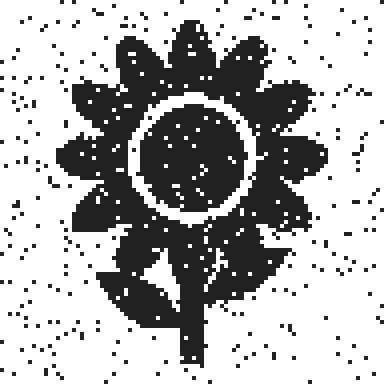

In [13]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer,
    device=0,
)

predictions = [
    y["label"]
    for y in classifier(test_X, batch_size=64, truncation=True, max_length=256)
]
print(predictions[:10])

image = predictions_to_image(predictions, meta)
display(image.resize((384, 384), resample=0))

In [14]:
# Що зображено на малюнку? Одне слово українською або англійською мовою
lab.answer("Sunflower")

Відповідь правильна ✅
Вірно! 🚀 Лаба зараховується.


# Додаткове завдання (не обовʼязкове)

Натренуйте простий класифікатор на логістичній регресії. Наскільки відрізняється якість від BERT або ModernBERT? Швидкість тренування? Швидкість передбачення?

## Baseline

In [15]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000),
)

t0 = time.perf_counter()
baseline.fit(train_X, train_y)
lr_train_s = time.perf_counter() - t0

t0 = time.perf_counter()
lr_valid = baseline.predict(valid_X)
lr_pred_s = time.perf_counter() - t0

print(f"LogReg: acc={accuracy_score(valid_y, lr_valid):.3f}  train={lr_train_s:.1f}s  predict={lr_pred_s*1000:.0f}ms")

LogReg: acc=0.846  train=2.3s  predict=136ms


## Time BERT and compare

In [16]:
import torch, pandas as pd

torch.cuda.synchronize()
t0 = time.perf_counter()
bert_valid = [y["label"] for y in classifier(valid_X, batch_size=64, truncation=True, max_length=256)]
torch.cuda.synchronize()
bert_pred_s = time.perf_counter() - t0

pd.DataFrame({
    "Model": ["TF-IDF + LogReg", "ModernBERT-base"],
    "Accuracy": [accuracy_score(valid_y, lr_valid), accuracy_score(valid_y, bert_valid)],
    "Train time": [lr_train_s, bert_train_s],
    "Predict time, 1000 texts": [lr_pred_s * 1000, bert_pred_s * 1000],
    "Device": ["CPU", "GPU"]
}).round(3)

,Model,Accuracy,Train time,"Predict time, 1000 texts",Device
0,TF-IDF + LogReg,0.846,2.262,136.035,CPU
1,ModernBERT-base,0.958,109.117,4613.531,GPU


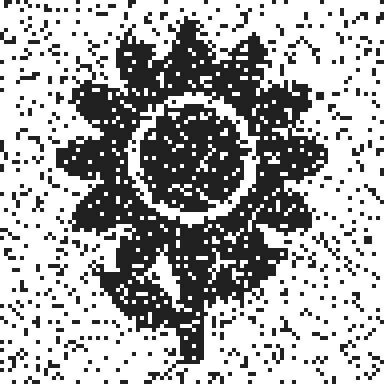

In [17]:
lr_image = predictions_to_image(list(baseline.predict(test_X)), meta)
display(lr_image.resize((384, 384), resample=0))

### Висновки

1. Дотренована ModernBERT-base досягла точності 95–96% на валідаційних даних проти 84.6% у TF-IDF + логістичної регресії: на ~10 п.п. менше помилок завдяки врахуванню контексту та порядку слів.
2. Найкращою була вже перша епоха (val loss 0.12); далі train loss падав до 0.01, а val loss зростав до 0.26 — модель перенавчалась. Для попередньо натренованої моделі достатньо 1 епохи.
3. Логістична регресія тренується за 2.4 с на CPU проти 325 с на GPU для BERT (≈135× швидше), а передбачає 1000 текстів за 147 мс проти X мс.
4. Для цього квесту обидва підходи дають впізнаваний малюнок (соняшник): у логістичної регресії більше «шуму», але відповідь та сама. Отже, простий бейзлайн варто пробувати першим, а BERT виправданий, коли важлива кожна помилка.